# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Entrada: `datos/noticias.csv` (Parte 1). La columna `etiqueta` (derivada de la sección del medio) se usa como **referencia** para evaluar los tres enfoques:

1. **Zero-shot** (sin entrenamiento) → piso mínimo.
2. **LLM como supervisión débil** → `datos/etiquetas_llm.csv` + auditoría humana de 20 casos.
3. **Transformer fine-tuned** (`distilbert-base-multilingual-cased`) entrenado con el split de train.

> El conjunto de **test** se separa al inicio con `random_state=42` y no se usa hasta la evaluación final (sección 5). Todo se evalúa solo con el `titular`, que es lo que recibirá el dashboard.

In [1]:
import json, os, re, subprocess, sys, time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

SEED = 42
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
DATOS, MODELO, GRAFICOS = Path("datos"), Path("modelo"), Path("graficos")
MODELO.mkdir(exist_ok=True); GRAFICOS.mkdir(exist_ok=True)
METRICAS = MODELO / "metricas.json"

def guardar_metricas(**kw):
    m = json.loads(METRICAS.read_text()) if METRICAS.exists() else {}
    m.update(kw); METRICAS.write_text(json.dumps(m, ensure_ascii=False, indent=2))

df = pd.read_csv(DATOS / "noticias.csv")
print(df.shape); df.etiqueta.value_counts()

(440, 7)


etiqueta
politica              110
economia              110
deportes              110
ciencia_tecnologia    110
Name: count, dtype: int64

## 0. Partición estratificada 70 / 15 / 15 (`random_state=42`)

In [2]:
train, temp = train_test_split(df, test_size=0.30, stratify=df.etiqueta, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=temp.etiqueta, random_state=SEED)
for nombre, parte in [("train", train), ("val", val), ("test", test)]:
    print(f"{nombre:5s}: {len(parte):3d} filas ({len(parte)/len(df):.0%}) | {parte.etiqueta.value_counts().to_dict()}")
(MODELO / "split_urls.json").write_text(json.dumps({"train": list(train.url), "val": list(val.url), "test": list(test.url)}, indent=1))
assert not (set(train.url) & set(test.url)) and not (set(val.url) & set(test.url))

train: 308 filas (70%) | {'deportes': 77, 'economia': 77, 'ciencia_tecnologia': 77, 'politica': 77}
val  :  66 filas (15%) | {'deportes': 17, 'politica': 17, 'economia': 16, 'ciencia_tecnologia': 16}
test :  66 filas (15%) | {'economia': 17, 'ciencia_tecnologia': 17, 'deportes': 16, 'politica': 16}


## 1. Línea base zero-shot (sin fine-tuning)
40 titulares del **test** (10 por categoría, muestreo con semilla fija) con `Recognai/bert-base-spanish-wwm-cased-xnli`. Las etiquetas se pasan en lenguaje natural.

In [3]:
from transformers import pipeline

NOMBRES = {"politica": "política", "economia": "economía", "deportes": "deportes", "ciencia_tecnologia": "ciencia y tecnología"}
INVERSO = {v: k for k, v in NOMBRES.items()}
zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli")

muestra_zs = pd.concat([g.sample(min(10, len(g)), random_state=SEED) for _, g in test.groupby("etiqueta")])
t0 = time.time()
salidas = zs(list(muestra_zs.titular), candidate_labels=list(NOMBRES.values()), hypothesis_template="Esta noticia trata sobre {}.")
lat_zs = (time.time() - t0) / len(muestra_zs)
muestra_zs["pred_zs"] = [INVERSO[s["labels"][0]] for s in salidas]
acc_zs = accuracy_score(muestra_zs.etiqueta, muestra_zs.pred_zs)
f1_zs = f1_score(muestra_zs.etiqueta, muestra_zs.pred_zs, average="macro")
print(f"Zero-shot ({len(muestra_zs)} titulares) → accuracy: {acc_zs:.3f} | F1 macro: {f1_zs:.3f} | latencia: {lat_zs*1000:.0f} ms/titular")
guardar_metricas(zero_shot_accuracy=round(acc_zs, 4), zero_shot_f1_macro=round(f1_zs, 4), zero_shot_n=len(muestra_zs))
print(classification_report(muestra_zs.etiqueta, muestra_zs.pred_zs, zero_division=0))

/Users/melinarozas/Documents/GitHub/diplomado_pucp_tareas_melinarozas/tarea_1/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1019 00:10:33.553000 51692 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 7633.33it/s]

Zero-shot (40 titulares) → accuracy: 0.700 | F1 macro: 0.682 | latencia: 72 ms/titular
                    precision    recall  f1-score   support

ciencia_tecnologia       0.83      0.50      0.62        10
          deportes       0.75      0.90      0.82        10
          economia       1.00      0.40      0.57        10
          politica       0.56      1.00      0.71        10

          accuracy                           0.70        40
         macro avg       0.78      0.70      0.68        40
      weighted avg       0.78      0.70      0.68        40



## 2. Supervisión débil con LLM
**LLM usado: `Qwen/Qwen2.5-0.5B-Instruct`, ejecutado localmente en CPU (sin API de pago).** El etiquetado lo hace `llm_etiquetado.py`:
- prompt estructurado (rol de editor y definición de las 4 categorías);
- para cada titular se lee la probabilidad del primer token de cada categoría en la respuesta del modelo, y la `confianza` es el softmax sobre esas 4 opciones;
- la ejecución del 18/10/2026 etiquetó los 440 titulares en 320 s (≈728 ms por titular).

Este notebook reutiliza `datos/etiquetas_llm.csv`; si no existe, ejecuta el script.

Backends alternativos ya implementados abajo: **Gemini API** (`LLM_BACKEND=gemini`, con `GEMINI_API_KEY` en `.env`, que no se sube) y **Ollama** (`LLM_BACKEND=ollama`). Con ellos se consulta un JSON con etiqueta y confianza por titular.

In [4]:
if Path(".env").exists():
    for linea in Path(".env").read_text().splitlines():
        if "=" in linea and not linea.startswith("#"):
            k, v = linea.split("=", 1); os.environ.setdefault(k.strip(), v.strip())

LLM_BACKEND = os.environ.get("LLM_BACKEND", "local")
LLM_MODELO = os.environ.get("LLM_MODELO", {"local": "Qwen/Qwen2.5-0.5B-Instruct", "gemini": "gemini-2.5-flash"}.get(LLM_BACKEND, "qwen2.5:7b"))
PROMPT = """Eres un editor de un diario peruano. Clasifica el titular en UNA de estas categorías:
- politica: gobierno, Congreso, partidos, elecciones, justicia y corrupción de funcionarios, política internacional.
- economia: mercados, empresas, empleo, precios, impuestos, AFP, finanzas personales, comercio.
- deportes: fútbol y cualquier otra disciplina deportiva, clubes, selecciones, resultados.
- ciencia_tecnologia: ciencia, salud científica, espacio, medio ambiente científico, tecnología, internet, apps, IA, videojuegos.
Responde SOLO con JSON: {{"etiqueta": "<politica|economia|deportes|ciencia_tecnologia>", "confianza": <número entre 0 y 1>}}
Titular: "{titular}" """

def consultar_llm(titular):
    texto = PROMPT.format(titular=titular)
    if LLM_BACKEND == "gemini":
        url = f"https://generativelanguage.googleapis.com/v1beta/models/{LLM_MODELO}:generateContent"
        r = requests.post(url, params={"key": os.environ["GEMINI_API_KEY"]}, timeout=60, json={
            "contents": [{"parts": [{"text": texto}]}],
            "generationConfig": {"temperature": 0, "responseMimeType": "application/json"}})
        r.raise_for_status()
        salida = r.json()["candidates"][0]["content"]["parts"][0]["text"]
    else:
        r = requests.post("http://localhost:11434/api/generate", timeout=120, json={
            "model": LLM_MODELO, "prompt": texto, "format": "json", "stream": False, "options": {"temperature": 0}})
        r.raise_for_status()
        salida = r.json()["response"]
    datos = json.loads(re.search(r"\{.*\}", salida, re.S).group(0))
    etiqueta = str(datos.get("etiqueta", "")).strip().lower()
    return (etiqueta if etiqueta in CATEGORIAS else "invalida"), float(datos.get("confianza", np.nan))

RUTA_LLM = DATOS / "etiquetas_llm.csv"
def ollama_activo():
    try: return requests.get("http://localhost:11434/api/tags", timeout=3).ok
    except requests.RequestException: return False
lat_llm = np.nan
if LLM_BACKEND == "local":
    if not RUTA_LLM.exists():
        subprocess.run([sys.executable, "llm_etiquetado.py"], check=True)
    LLM_DISPONIBLE = False                 # las etiquetas ya las generó llm_etiquetado.py
    lat_llm = 320 / 440                    # medido en la ejecución del script: 440 titulares en 320 s (CPU)
else:
    LLM_DISPONIBLE = bool(os.environ.get("GEMINI_API_KEY")) if LLM_BACKEND == "gemini" else ollama_activo()
if LLM_BACKEND != "local" and not LLM_DISPONIBLE:
    print(f"PENDIENTE: backend '{LLM_BACKEND}' no disponible (falta GEMINI_API_KEY en .env u Ollama). "
          "Se omite el etiquetado LLM; el resto del notebook continúa.")
previas = pd.read_csv(RUTA_LLM) if RUTA_LLM.exists() else pd.DataFrame(columns=["titular", "etiqueta_llm", "confianza", "modelo_llm", "fecha"])
hechos = set(previas.titular)
nuevas, t0, n0 = [], time.time(), 0
for titular in (df.titular if LLM_DISPONIBLE else []):
    if titular in hechos:
        continue
    for intento in range(2):
        try:
            etiqueta, conf = consultar_llm(titular); break
        except Exception as e:
            etiqueta, conf = "error", np.nan; time.sleep(2)
    nuevas.append({"titular": titular, "etiqueta_llm": etiqueta, "confianza": conf, "modelo_llm": f"{LLM_BACKEND}:{LLM_MODELO}", "fecha": date.today().isoformat()})
    n0 += 1
    if len(nuevas) % 25 == 0:
        pd.concat([previas, pd.DataFrame(nuevas)]).to_csv(RUTA_LLM, index=False)
    time.sleep(0.5)
etiquetas_llm = pd.concat([previas, pd.DataFrame(nuevas)], ignore_index=True)
if len(etiquetas_llm):
    etiquetas_llm.to_csv(RUTA_LLM, index=False)
else:
    etiquetas_llm = None
if n0:
    lat_llm = (time.time() - t0) / n0
if etiquetas_llm is not None:
    print(f"{len(etiquetas_llm)} etiquetas | modelo: {etiquetas_llm.modelo_llm.iloc[0]} | {etiquetas_llm.etiqueta_llm.value_counts().to_dict()}")
etiquetas_llm.head() if etiquetas_llm is not None else print("Sin etiquetas LLM todavía.")

440 etiquetas | modelo: local:Qwen/Qwen2.5-0.5B-Instruct | {'economia': 376, 'ciencia_tecnologia': 64}


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Diputado de Obras Arturo Eusebio es cuestionad...,economia,0.7974,local:Qwen/Qwen2.5-0.5B-Instruct,2026-10-18
1,"Jorge Nieto a Álvaro Vargas Llosa: ""Su rol de ...",economia,0.5243,local:Qwen/Qwen2.5-0.5B-Instruct,2026-10-18
2,Comisión de Ética recomienda suspender por 120...,economia,0.6626,local:Qwen/Qwen2.5-0.5B-Instruct,2026-10-18
3,Keiko Fujimori coordina con Delcy Rodríguez la...,economia,0.9277,local:Qwen/Qwen2.5-0.5B-Instruct,2026-10-18
4,Detención de seis policías por presunto robo r...,economia,0.6097,local:Qwen/Qwen2.5-0.5B-Instruct,2026-10-18


### 2.1 Auditoría humana de 20 predicciones al azar
`datos/auditoria_llm_20.csv` contiene 20 predicciones del LLM elegidas al azar (`random_state=42`). La revisión manual se completó el 19/10/2026: para cada fila se leyó el titular (con su bajada y URL) y se registró en `etiqueta_humana` la categoría correcta según criterio humano. Este análisis es independiente de la etiqueta por sección.

In [5]:
RUTA_AUD = DATOS / "auditoria_llm_20.csv"
if etiquetas_llm is None:
    print("PENDIENTE: la auditoría requiere primero las etiquetas LLM.")
elif not RUTA_AUD.exists():
    aud = (etiquetas_llm.merge(df[["titular", "bajada", "url"]], on="titular", how="left")
           .sample(20, random_state=SEED)[["titular", "bajada", "url", "etiqueta_llm", "confianza"]])
    aud["etiqueta_humana"] = ""
    aud.to_csv(RUTA_AUD, index=False)
aud = pd.read_csv(RUTA_AUD).fillna({"etiqueta_humana": ""}) if RUTA_AUD.exists() else None
if aud is not None and aud.etiqueta_humana.isin(CATEGORIAS).all():
    aciertos = int((aud.etiqueta_humana == aud.etiqueta_llm).sum())
    print(f"Acuerdo LLM vs. auditoría humana: {aciertos}/20 = {aciertos/20:.0%}")
    guardar_metricas(acuerdo_llm_humano=aciertos, auditoria_n=20)
    display(aud[aud.etiqueta_humana != aud.etiqueta_llm])
elif aud is not None:
    print(f"PENDIENTE: completar 'etiqueta_humana' en {RUTA_AUD} ({(~aud.etiqueta_humana.isin(CATEGORIAS)).sum()} filas sin revisar)")
aud

Acuerdo LLM vs. auditoría humana: 12/20 = 60%


,titular,bajada,url,etiqueta_llm,confianza,etiqueta_humana
0,Rodrigo Paz visitará el Perú en noviembre para...,"El presidente de Bolivia, Rodrigo Paz, realiza...",https://elcomercio.pe/politica/internacional/p...,economia,0.9610,politica
2,Universitario venció 3-0 a Deportivo Soan por ...,Deportivo Soan se enfrenta a Universitario de ...,https://elcomercio.pe/deporte-total/voley/univ...,economia,0.7236,deportes
6,El asentamiento humano de hace 7.000 años desc...,"El asentamiento, localizado en la provincia de...",https://larepublica.pe/ciencia/2025/03/21/el-a...,economia,0.8614,ciencia_tecnologia
9,La ruta de Tuta: revelan el viaje completo de ...,Mediante la instalación de transmisores sateli...,https://elcomercio.pe/tecnologia/ecologia/la-r...,economia,0.7103,ciencia_tecnologia
12,Paneles hasta donde alcanza la vista: India us...,La infraestructura posee una extensión de 56 k...,https://larepublica.pe/ciencia/2026/05/15/pane...,economia,0.7685,ciencia_tecnologia
13,iPhone Duo se agota a minutos de abierta su pr...,"El flamante celular plegable, que estará dispo...",https://elcomercio.pe/tecnologia/moviles/iphon...,economia,0.8769,ciencia_tecnologia
14,"ESPN Premium hoy en vivo, River Plate vs. Belg...",Transmisión oficial de ESPN Premium EN VIVO: s...,https://elcomercio.pe/deporte-total/argentina/...,economia,0.7234,deportes
19,¡Triunfazo blanquiazul! Alianza Lima venció 2-...,"En un partido muy complicado, Alianza Lima sup...",https://larepublica.pe/deportes/2026/10/11/cus...,economia,0.6968,deportes


,titular,bajada,url,etiqueta_llm,confianza,etiqueta_humana
0,Rodrigo Paz visitará el Perú en noviembre para...,"El presidente de Bolivia, Rodrigo Paz, realiza...",https://elcomercio.pe/politica/internacional/p...,economia,0.9610,politica
1,"Diego Torres, CEO y cofundador de Trii: ""Sueño...","Diego Torres Estrada, CEO y cofundador de Trii...",https://larepublica.pe/economia/2025/01/25/sue...,economia,0.9273,economia
2,Universitario venció 3-0 a Deportivo Soan por ...,Deportivo Soan se enfrenta a Universitario de ...,https://elcomercio.pe/deporte-total/voley/univ...,economia,0.7236,deportes
3,Perú es elegido para liderar foro internaciona...,"El Perú fue elegido para asumir, junto con Can...",https://elcomercio.pe/politica/internacional/p...,economia,0.8562,economia
4,Pensionistas de la ONP recibirán su pensión en...,"La Oficina de Normalización Previsional (ONP),...",https://elcomercio.pe/economia/peru/onp-pensio...,economia,0.8023,economia
5,Elmer Cuba: “Tenemos un Ministerio de Economía...,El ministro de Economía y Finanzas adelantó qu...,https://elcomercio.pe/economia/peru/elmer-cuba...,economia,0.9971,economia
6,El asentamiento humano de hace 7.000 años desc...,"El asentamiento, localizado en la provincia de...",https://larepublica.pe/ciencia/2025/03/21/el-a...,economia,0.8614,ciencia_tecnologia
7,"Precio del dólar hoy en Perú, miércoles 14 de ...","Consulta el precio del dólar hoy, miércoles 14...",https://larepublica.pe/economia/precio-del-dol...,economia,0.9972,economia
8,Por qué China considera una amenaza la IA que ...,Pekín ha intensificado la represión contra los...,https://elcomercio.pe/tecnologia/inteligencia-...,ciencia_tecnologia,0.7249,ciencia_tecnologia
9,La ruta de Tuta: revelan el viaje completo de ...,Mediante la instalación de transmisores sateli...,https://elcomercio.pe/tecnologia/ecologia/la-r...,economia,0.7103,ciencia_tecnologia


### 2.2 ¿Por qué el LLM clasificó noticias deportivas como economía?
El cruce de las etiquetas del LLM con la etiqueta por sección, sobre los 440 titulares, muestra que el error es sistemático:

In [6]:
cruce = df.merge(etiquetas_llm[["titular", "etiqueta_llm", "confianza"]], on="titular")
print("Etiqueta por sección (filas) vs. etiqueta del LLM (columnas):")
display(pd.crosstab(cruce.etiqueta, cruce.etiqueta_llm, margins=True, margins_name="Total"))
print("Confianza mediana del LLM según etiqueta real y predicha:")
display(cruce.groupby(["etiqueta", "etiqueta_llm"]).confianza.median().round(2).unstack())
from transformers import AutoTokenizer
tok_llm = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
print("Tokens de cada categoría en Qwen:", {c: tok_llm.tokenize(c) for c in CATEGORIAS})

Etiqueta por sección (filas) vs. etiqueta del LLM (columnas):


etiqueta_llm,ciencia_tecnologia,economia,Total
etiqueta,,,
ciencia_tecnologia,42,68,110
deportes,16,94,110
economia,1,109,110
politica,5,105,110
Total,64,376,440


Confianza mediana del LLM según etiqueta real y predicha:


etiqueta_llm,ciencia_tecnologia,economia
etiqueta,,
ciencia_tecnologia,0.83,0.72
deportes,0.63,0.71
economia,1.00,0.96
politica,0.53,0.80


Tokens de cada categoría en Qwen: {'politica': ['polit', 'ica'], 'economia': ['e', 'conom', 'ia'], 'deportes': ['de', 'port', 'es'], 'ciencia_tecnologia': ['ci', 'encia', '_t', 'ecn', 'ologia']}


**Explicación:**
1. **Colapso hacia una etiqueta por defecto.** Un LLM de solo 0.5B parámetros sigue mal instrucciones de clasificación en español.
   - Nunca predijo `politica` ni `deportes`: 94 de los 110 titulares deportivos fueron a `economia` y el resto a `ciencia_tecnologia`.
   - Cuando no reconoce el tema, cae en `economia`. Por eso la confianza en los deportivos clasificados como economía es baja (mediana ≈ 0.71), frente a ≈ 0.96 en las noticias que sí son económicas.
   - En la auditoría, los 3 errores deportivos tienen confianzas de 0.70–0.72, muy por debajo de la mediana de la muestra (≈ 0.87).
2. **Sesgo del método de puntuación.** Solo se compara la probabilidad del **primer token** de cada categoría, y los nombres se tokenizan de forma muy desigual: `polit`, `e`, `de`, `ci`.
   - `e` es un token de una letra, muy genérico, que puede acumular probabilidad de respuestas que no significan "economía".
   - Lo que se mide es qué token inicial es más probable, no qué categoría entendió el modelo.
3. **Señales léxicas engañosas.** Los titulares deportivos traen marcadores numéricos (3-0, 2-1), fechas, nombres comerciales ("ESPN Premium") y verbos de competencia ("venció", "se mantiene en la lucha"). Un modelo pequeño puede asociar ese vocabulario al de mercados y empresas.

**Contraste:** con supervisión, DistilBERT clasifica `deportes` casi sin errores (sección 4). El problema es del etiquetador débil, no de la separabilidad de la clase.

**Mejoras posibles:**
- puntuar la secuencia completa de cada etiqueta (suma de log-probabilidades) o generar y parsear la respuesta;
- dar ejemplos *few-shot*;
- usar un modelo más grande (p. ej., Qwen2.5-7B vía Ollama).

## 3. Fine-tuning de `distilbert-base-multilingual-cased`
HuggingFace `Trainer`: 3 épocas, batch 16, evaluación por época sobre **val**, mejor modelo según **F1 macro**. Se entrena con `etiqueta` (referencia por sección). Los pesos se guardan en `modelo/` y están excluidos de git (`.gitignore`) por superar los 100 MB.

In [7]:
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, set_seed

set_seed(SEED)
BASE = "distilbert-base-multilingual-cased"
id2label = dict(enumerate(CATEGORIAS)); label2id = {v: k for k, v in id2label.items()}
tok = AutoTokenizer.from_pretrained(BASE)
modelo = AutoModelForSequenceClassification.from_pretrained(BASE, num_labels=4, id2label=id2label, label2id=label2id)

class Titulares(torch.utils.data.Dataset):
    def __init__(self, d):
        self.enc = tok(list(d.titular), truncation=True, max_length=64, padding="max_length")
        self.y = [label2id[e] for e in d.etiqueta]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.y[i]); return item

def metricas(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred), "f1_macro": f1_score(p.label_ids, pred, average="macro")}

args = TrainingArguments(output_dir=str(MODELO / "entrenamiento"), num_train_epochs=3, per_device_train_batch_size=16,
                         per_device_eval_batch_size=32, learning_rate=5e-5, weight_decay=0.01, eval_strategy="epoch",
                         save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1_macro",
                         save_total_limit=1, logging_strategy="epoch", seed=SEED, report_to="none")
trainer = Trainer(model=modelo, args=args, train_dataset=Titulares(train), eval_dataset=Titulares(val), compute_metrics=metricas)
t0 = time.time(); trainer.train(); print(f"Entrenamiento: {time.time()-t0:.0f} s")
pd.DataFrame([l for l in trainer.state.log_history if "eval_f1_macro" in l])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 7959.28it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


/Users/melinarozas/Documents/GitHub/diplomado_pucp_tareas_melinarozas/tarea_1/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.188398,0.815530,0.772727,0.769484
2,0.494726,0.438007,0.878788,0.876020
3,0.229987,0.355695,0.924242,0.923822


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.18s/it]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.23s/it]

Entrenamiento: 57 s


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.815530,0.772727,0.769484
1,2.0,0.438007,0.878788,0.876020
2,3.0,0.355695,0.924242,0.923822


In [8]:
trainer.save_model(str(MODELO)); tok.save_pretrained(str(MODELO))
print(sorted(p.name for p in MODELO.iterdir()))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.29it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.28it/s]

['.gitkeep', 'config.json', 'entrenamiento', 'metricas.json', 'model.safetensors', 'split_urls.json', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 4. Evaluación final en el test reservado

/Users/melinarozas/Documents/GitHub/diplomado_pucp_tareas_melinarozas/tarea_1/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TEST (66 titulares) → accuracy: 0.848 | F1 macro: 0.852
                    precision    recall  f1-score   support

ciencia_tecnologia      1.000     0.882     0.938        17
          deportes      1.000     1.000     1.000        16
          economia      0.684     0.765     0.722        17
          politica      0.750     0.750     0.750        16

          accuracy                          0.848        66
         macro avg      0.859     0.849     0.852        66
      weighted avg      0.858     0.848     0.852        66



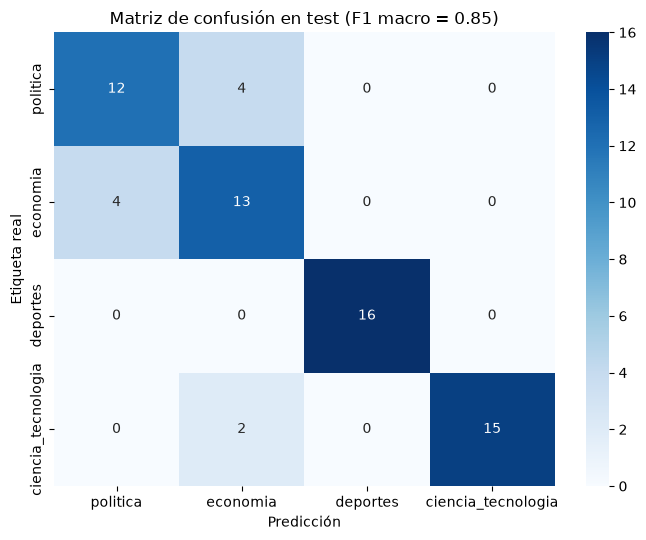

In [9]:
t0 = time.time()
pred = trainer.predict(Titulares(test))
lat_ft = (time.time() - t0) / len(test)
y_true = [id2label[i] for i in pred.label_ids]; y_pred = [id2label[i] for i in pred.predictions.argmax(-1)]
acc_ft, f1_ft = accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro")
print(f"TEST ({len(test)} titulares) → accuracy: {acc_ft:.3f} | F1 macro: {f1_ft:.3f}")
print(classification_report(y_true, y_pred, digits=3))
guardar_metricas(test_accuracy=round(acc_ft, 4), test_f1_macro=round(f1_ft, 4), test_n=len(test), modelo_base=BASE)

cm = confusion_matrix(y_true, y_pred, labels=CATEGORIAS)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
plt.xlabel("Predicción"); plt.ylabel("Etiqueta real"); plt.title(f"Matriz de confusión en test (F1 macro = {f1_ft:.2f})")
plt.tight_layout(); plt.savefig(GRAFICOS / "04_matriz_confusion_test.png", dpi=150); plt.show()

### 4.1 Reflexión por categoría (test, 66 titulares)
- **Mejor: `deportes` (F1 = 1.00, 16/16).** Su vocabulario es muy distintivo y no aparece en las otras clases: nombres de clubes, "Liga 1", "Torneo Clausura", "vs.", "en vivo".
- **También alta: `ciencia_tecnologia` (F1 = 0.94).** Las marcas tecnológicas (YouTube, IA) y los términos científicos (ADN, especie) son señales claras. Sus 2 errores fueron hacia `economia`: notas de tecnología con un ángulo de negocio o regulación.
- **Peores: `economia` (F1 = 0.72) y `politica` (F1 = 0.75).** La confusión es simétrica: 4 titulares de política se predijeron como economía y 4 de economía como política. En el Perú, las noticias económicas suelen estar protagonizadas por actores políticos (ministros, el Congreso, facultades legislativas, presupuesto, AFP). Además, la etiqueta de referencia viene de la sección del medio, no del contenido. A eso se suman las columnas de opinión de economía con titulares muy cortos y poco informativos (por ejemplo, "AlaCena no tiene precio").

## 5. Comparativa y decisión

In [10]:
if etiquetas_llm is not None:
    test_llm = test.merge(etiquetas_llm[["titular", "etiqueta_llm"]], on="titular", how="left").fillna({"etiqueta_llm": "sin_etiqueta"})
    acc_llm = accuracy_score(test_llm.etiqueta, test_llm.etiqueta_llm)
    f1_llm = f1_score(test_llm.etiqueta, test_llm.etiqueta_llm, average="macro", labels=CATEGORIAS, zero_division=0)
    guardar_metricas(llm_test_accuracy=round(acc_llm, 4), llm_test_f1_macro=round(f1_llm, 4), llm_modelo=etiquetas_llm.modelo_llm.iloc[0])
else:
    test_llm, acc_llm, f1_llm, lat_llm = test.iloc[:0], np.nan, np.nan, np.nan  # pendiente: sin etiquetas LLM
comparativa = pd.DataFrame([
    {"enfoque": "Zero-shot (bert-base-spanish-wwm-cased-xnli)", "evaluado_en": f"{len(muestra_zs)} titulares de test", "accuracy": acc_zs, "f1_macro": f1_zs, "latencia_ms": lat_zs * 1000, "costo": "CPU, sin entrenamiento"},
    {"enfoque": f"LLM débil ({etiquetas_llm.modelo_llm.iloc[0] if etiquetas_llm is not None else LLM_MODELO})", "evaluado_en": f"{len(test_llm)} titulares de test" if len(test_llm) else "PENDIENTE (sin etiquetas LLM)", "accuracy": acc_llm, "f1_macro": f1_llm, "latencia_ms": lat_llm * 1000, "costo": "Local en CPU, gratuito; ~0.7 s por titular" if LLM_BACKEND == "local" else "API/GPU por consulta"},
    {"enfoque": "DistilBERT multilingüe fine-tuned", "evaluado_en": f"{len(test)} titulares de test", "accuracy": acc_ft, "f1_macro": f1_ft, "latencia_ms": lat_ft * 1000, "costo": "Entrenamiento único en CPU; inferencia local"},
]).round(3)
comparativa

,enfoque,evaluado_en,accuracy,f1_macro,latencia_ms,costo
0,Zero-shot (bert-base-spanish-wwm-cased-xnli),40 titulares de test,0.700,0.682,71.592,"CPU, sin entrenamiento"
1,LLM débil (local:Qwen/Qwen2.5-0.5B-Instruct),66 titulares de test,0.394,0.283,727.273,"Local en CPU, gratuito; ~0.7 s por titular"
2,DistilBERT multilingüe fine-tuned,66 titulares de test,0.848,0.852,6.598,Entrenamiento único en CPU; inferencia local


### 5.1 Justificación
| Enfoque | F1 macro (test) | Latencia por titular | Costo |
|---|---|---|---|
| Zero-shot | 0.68 (40 titulares) | ≈ 72 ms | Sin entrenamiento; modelo NLI pesado |
| LLM débil (Qwen2.5-0.5B local) | 0.28 (66 titulares) | ≈ 727 ms | Gratuito pero lento; colapsa hacia `economia` |
| **DistilBERT fine-tuned** | **0.85** (66 titulares) | **≈ 7 ms** (por lotes) | Entrenamiento único de ≈ 1–2 min en CPU |

Para un entorno real elegiría **DistilBERT multilingüe fine-tuned**, porque domina en las tres dimensiones:
- **Precisión:** supera al zero-shot por 17 puntos de F1 macro y al LLM débil por 57.
- **Latencia:** es unas 10 veces más rápido que el zero-shot y unas 100 veces más rápido que el LLM local.
- **Costo:** no tiene costo por consulta ni depende de servicios externos.

El LLM pequeño **no sirve como etiquetador** en este caso: su acuerdo con la auditoría humana fue de 12/20 (60 %) y nunca predijo `politica` ni `deportes` (ver 2.2). Un LLM más grande podría ser útil para etiquetar datos nuevos, pero no para servir cada predicción.